# Onde o Novo Bolsa Família pesa mais

### Cruzando os pagamentos do Portal da Transparência com população e PIB municipal do IBGE em MongoDB

**Trabalho de Banco de Dados — itens (h) conexão com PyMongo e (i) visualização dos dados**

| Integrante | RA |
|---|---|
| Antonio Adolfo Geraldino Bernardo | 828561 |
| Rafael Yugo Hashimoto | 834417 |
| Rafaela Silva Ruis | 834416 |

---

**Base 1 — Novo Bolsa Família** (Portal da Transparência do Governo Federal):
57.174.504 parcelas pagas nas competências 06/2026, 07/2026 e 08/2026.

**Base 2 — IBGE**: os 5.570 municípios brasileiros com hierarquia geográfica,
população estimada para 2026 e PIB municipal de 2015 a 2023.

**Pergunta que o notebook responde:** em quais estados e municípios o programa
transfere mais dinheiro por habitante e atende a maior fatia das famílias — e
como isso se relaciona com a riqueza local.

## 1. Conexão com o MongoDB (item h)

A célula abaixo funciona em três modos e escolhe sozinha o que estiver disponível:

| Modo | Quando usar | O que faz |
|---|---|---|
| `local` | notebook rodando na mesma máquina do banco | conecta direto em `localhost:27017` |
| `atlas` | se o grupo criar um cluster no MongoDB Atlas | usa a *connection string* colada em `URI_ATLAS` |
| `colab` | **Google Colab** | instala o MongoDB dentro da máquina virtual do Colab e restaura o pacote `dump_colab.tgz`, baixado do repositório (ou enviado à mão) |

> **Por que o Colab precisa do modo `colab`?** A máquina virtual do Colab roda na
> nuvem do Google e não enxerga o `localhost` do computador de quem está
> executando. O caminho oficial para contornar isso seria o *runtime local* com a
> extensão `jupyter_http_over_ws`, mas esse pacote foi descontinuado e não é
> compatível com as versões atuais do Jupyter. Por isso o notebook sobe o próprio
> servidor MongoDB dentro da VM do Colab e restaura ali um dump com as coleções
> agregadas do trabalho — assim ele roda de ponta a ponta no Colab, sem depender
> de nenhuma máquina externa.

In [1]:
# Dependências (no Colab a instalação é necessária; localmente não faz nada)
%pip install --quiet pymongo pandas matplotlib requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import shutil
import subprocess
import sys
import tarfile
import time
import urllib.request
from pathlib import Path

from pymongo import MongoClient

# ----------------------------------------------------------------- ajustes --
MODO = "auto"          # "auto" | "local" | "atlas" | "colab"
URI_LOCAL = "mongodb://localhost:27017/brasil_bf"
URI_ATLAS = ""         # cole aqui a connection string do Atlas, se for usar
BANCO = "brasil_bf"

# Pacote gerado por notebook/gerar_dump_colab.sh. No Colab ele e baixado do
# proprio repositorio; se URL_DUMP estiver vazia, o notebook pede o upload.
ARQUIVO_DUMP = "dump_colab.tgz"
URL_DUMP = ""   # ex.: https://raw.githubusercontent.com/USUARIO/REPO/main/dados/dump_colab.tgz

VERSAO_MONGO = "8.0.15"
VERSAO_TOOLS = "100.13.0"
URL_MONGO = (f"https://fastdl.mongodb.org/linux/"
             f"mongodb-linux-x86_64-ubuntu2204-{VERSAO_MONGO}.tgz")
URL_TOOLS = (f"https://fastdl.mongodb.org/tools/db/"
             f"mongodb-database-tools-ubuntu2204-x86_64-{VERSAO_TOOLS}.tgz")


def tenta_conectar(uri, ms=4000):
    """Devolve o Database se a URI responder ao ping, senão None."""
    if not uri:
        return None
    try:
        cliente = MongoClient(uri, serverSelectionTimeoutMS=ms)
        cliente.admin.command("ping")
        return cliente[BANCO]
    except Exception:
        return None


def rodando_no_colab():
    return "google.colab" in sys.modules


def baixa_e_extrai(url, destino):
    tgz = Path("/tmp") / Path(url).name
    if not tgz.exists():
        print(f"  baixando {tgz.name} ...")
        urllib.request.urlretrieve(url, tgz)
    with tarfile.open(tgz) as arquivo:
        arquivo.extractall(destino)
    return next(Path(destino).glob(Path(url).name.replace(".tgz", "")))


def sobe_mongo_no_colab():
    """Instala e inicia um mongod dentro da VM do Colab e restaura o dump."""
    base = Path("/content/mongodb")
    base.mkdir(parents=True, exist_ok=True)
    (base / "data").mkdir(exist_ok=True)

    print("1/4 instalando o servidor MongoDB na VM do Colab")
    pasta_mongo = baixa_e_extrai(URL_MONGO, base)
    print("2/4 instalando as ferramentas (mongorestore)")
    pasta_tools = baixa_e_extrai(URL_TOOLS, base)

    binarios = str(pasta_mongo / "bin") + ":" + str(pasta_tools / "bin")
    os.environ["PATH"] = binarios + ":" + os.environ["PATH"]

    print("3/4 iniciando o mongod")
    subprocess.run(["mongod", "--dbpath", str(base / "data"),
                    "--logpath", str(base / "mongod.log"),
                    "--bind_ip", "127.0.0.1", "--port", "27017", "--fork"],
                   check=True)
    for _ in range(30):
        if tenta_conectar(URI_LOCAL, 1000) is not None:
            break
        time.sleep(1)

    if not Path(ARQUIVO_DUMP).exists() and URL_DUMP:
        print(f"4/4 baixando {ARQUIVO_DUMP} do repositorio")
        urllib.request.urlretrieve(URL_DUMP, ARQUIVO_DUMP)
    if not Path(ARQUIVO_DUMP).exists():
        print(f"4/4 envie o arquivo {ARQUIVO_DUMP} (que acompanha o trabalho)")
        from google.colab import files
        enviados = files.upload()
        nome = next(iter(enviados))
        if nome != ARQUIVO_DUMP:
            shutil.move(nome, ARQUIVO_DUMP)
    else:
        print("4/4 restaurando o dump")
    with tarfile.open(ARQUIVO_DUMP) as pacote:
        pacote.extractall("/content")
    subprocess.run(["mongorestore", "--gzip", "--drop", "--quiet",
                    "/content/dump_colab"], check=True)
    return tenta_conectar(URI_LOCAL)


# ----------------------------------------------------------------- conexão --
db = None
if MODO in ("auto", "local"):
    db = tenta_conectar(URI_LOCAL)
    if db is not None:
        print("conectado ao MongoDB local")
if db is None and MODO in ("auto", "atlas"):
    db = tenta_conectar(URI_ATLAS)
    if db is not None:
        print("conectado ao MongoDB Atlas")
if db is None and (MODO == "colab" or rodando_no_colab()):
    db = sobe_mongo_no_colab()
    print("conectado ao MongoDB da VM do Colab")
if db is None:
    raise SystemExit("nenhum MongoDB disponível - revise o MODO acima")

print("versão do servidor:", db.client.server_info()["version"])

conectado ao MongoDB local
versão do servidor: 8.0.31


### Coleções disponíveis (item e, conferido pelo Python)

In [3]:
import pandas as pd

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

inventario = []
for nome in sorted(db.list_collection_names()):
    inventario.append({
        "coleção": nome,
        "documentos": db[nome].estimated_document_count(),
        "índices": len(db[nome].index_information()),
    })
pd.DataFrame(inventario)

,coleção,documentos,índices
0,de_para_siafi_ibge,5571,3
1,municipios_ibge,5571,5
2,pagamentos_bf,57174504,4
3,pib_serie_ibge,50139,3
4,resumo_municipio_competencia,16713,4
5,system.profile,4,0


In [4]:
# Parâmetros usados nas visualizações
COMPETENCIA = 202608          # mês de pagamento analisado
RESUMO = "resumo_municipio_competencia"   # visão materializada criada com $merge

CORES_REGIAO = {
    "Norte": "#2E7D32", "Nordeste": "#EF6C00", "Sudeste": "#1565C0",
    "Sul": "#6A1B9A", "Centro-Oeste": "#C62828",
}

# Procura a pasta saidas/ subindo a partir do diretório atual; assim o
# notebook grava no lugar certo tanto rodando da raiz do projeto quanto de
# dentro de notebook/. No Colab, cai em /content/graficos.
PASTA = None
for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "saidas").is_dir():
        PASTA = base / "saidas" / "graficos"
        break
if PASTA is None:
    PASTA = Path("graficos")
PASTA.mkdir(parents=True, exist_ok=True)
print("gráficos serão salvos em:", PASTA)

import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.facecolor": "white",
})


def moeda(valor, _=None):
    return ("R$ " + f"{valor:,.0f}").replace(",", ".")


def agregar(colecao, pipeline):
    inicio = time.perf_counter()
    dados = list(db[colecao].aggregate(pipeline, allowDiskUse=True))
    print(f"{colecao}: {len(dados)} documentos em "
          f"{(time.perf_counter()-inicio)*1000:,.0f} ms")
    return pd.DataFrame(dados)

print("parâmetros carregados")

gráficos serão salvos em: /home/rafaela/Documentos/Semestre 6/BDCD/t1/saidas/graficos


parâmetros carregados


## 2. Visualização 1 — Quanto o programa transfere por habitante em cada estado

**Objetivo.** Ordenar as 27 unidades da federação pelo valor pago por habitante,
mostrando que o programa não se distribui de forma homogênea pelo país.

**Atributos envolvidos.** Da Base 1: `total_pago` e `parcelas_regulares`
(agregados por `uf` na competência 202608). Da Base 2: `populacao` (estimativa
IBGE 2026) e `regiao`, usados para normalizar e para colorir as barras.

In [5]:
pipeline_uf = [
    {"$match": {"competencia": COMPETENCIA}},
    {"$group": {
        "_id": "$uf",
        "regiao": {"$first": "$regiao"},
        "total_pago": {"$sum": "$total_pago"},
        "familias": {"$sum": "$parcelas_regulares"},
        "populacao": {"$sum": "$populacao"},
        "municipios": {"$sum": 1},
    }},
    {"$addFields": {
        "valor_per_capita": {"$divide": ["$total_pago", "$populacao"]},
        "familias_por_100_hab": {
            "$multiply": [100, {"$divide": ["$familias", "$populacao"]}]},
        "valor_medio_familia": {"$divide": ["$total_pago", "$familias"]},
    }},
    {"$sort": {"valor_per_capita": -1}},
]

uf = agregar(RESUMO, pipeline_uf).rename(columns={"_id": "uf"})
uf.head(10)

resumo_municipio_competencia: 27 documentos em 45 ms


,uf,regiao,total_pago,familias,populacao,municipios,valor_per_capita,familias_por_100_hab,valor_medio_familia
0,MA,Nordeste,"797,754,248.00",1144771,7024557,217,113.57,16.30,696.87
1,PI,Nordeste,"363,458,506.00",537573,3392617,224,107.13,15.85,676.11
2,AL,Nordeste,"343,850,004.00",499212,3221128,102,106.75,15.50,688.79
3,BA,Nordeste,"1,558,392,484.00",2336520,14889472,417,104.66,15.69,666.97
4,PE,Nordeste,"994,566,644.00",1479130,9583176,185,103.78,15.43,672.40
5,SE,Nordeste,"238,428,800.00",355522,2307255,75,103.34,15.41,670.64
6,AP,Norte,"81,967,870.00",113427,809953,16,101.20,14.00,722.65
7,AC,Norte,"89,674,058.00",123984,887794,22,101.01,13.97,723.27
8,AM,Norte,"440,390,119.00",606155,4360926,62,100.99,13.90,726.53
9,PB,Nordeste,"418,329,416.00",620637,4182828,223,100.01,14.84,674.03


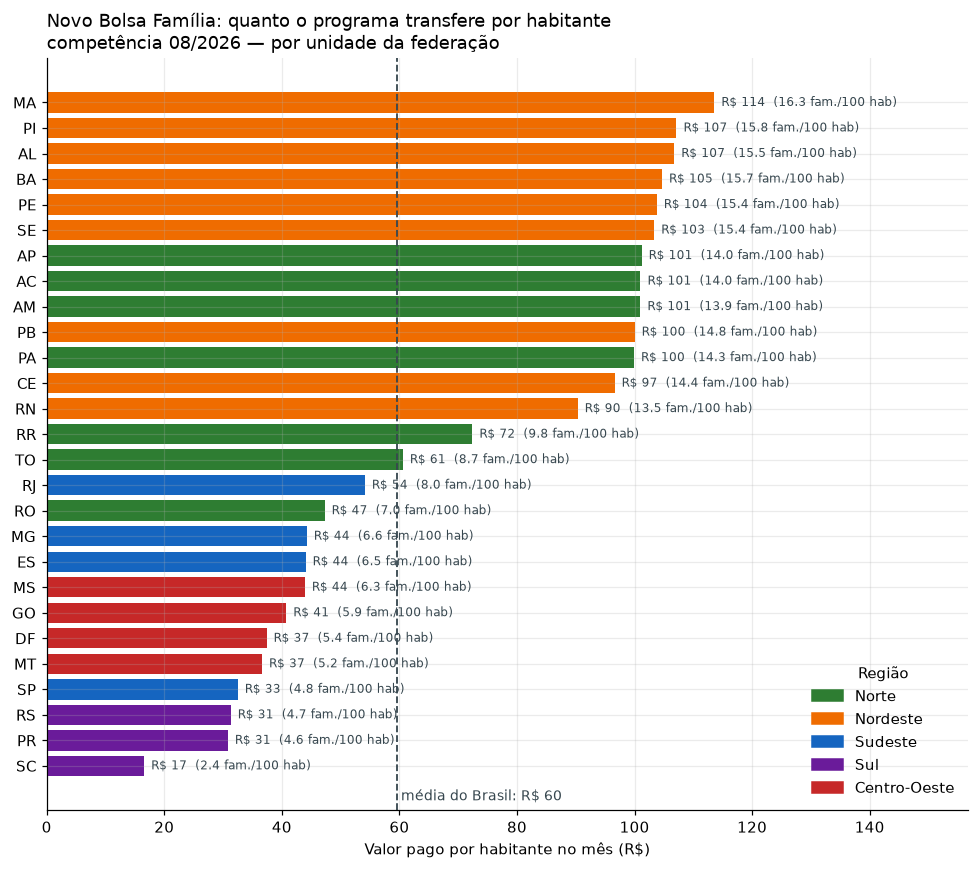

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))

ordem = uf.sort_values("valor_per_capita")
cores = [CORES_REGIAO[r] for r in ordem["regiao"]]
barras = ax.barh(ordem["uf"], ordem["valor_per_capita"], color=cores)

media = uf["total_pago"].sum() / uf["populacao"].sum()
ax.axvline(media, color="#37474F", linestyle="--", linewidth=1.2)
ax.text(media, -1.2, f" média do Brasil: {moeda(media)}",
        color="#37474F", fontsize=9, va="center")

for barra, valor, familias in zip(barras, ordem["valor_per_capita"],
                                  ordem["familias_por_100_hab"]):
    ax.text(barra.get_width() + 1.2, barra.get_y() + barra.get_height() / 2,
            f"{moeda(valor)}  ({familias:.1f} fam./100 hab)",
            va="center", fontsize=8, color="#37474F")

ax.set_xlim(0, ordem["valor_per_capita"].max() * 1.38)
ax.set_xlabel("Valor pago por habitante no mês (R$)")
ax.set_title("Novo Bolsa Família: quanto o programa transfere por habitante\n"
             f"competência {str(COMPETENCIA)[4:]}/{str(COMPETENCIA)[:4]} — "
             "por unidade da federação", fontsize=12, loc="left")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=r)
                   for r, c in CORES_REGIAO.items()],
          loc="lower right", frameon=False, title="Região")
fig.tight_layout()
fig.savefig(PASTA / "viz1_valor_per_capita_por_uf.png", bbox_inches="tight")
plt.show()

**O que se conclui.** O valor transferido por habitante no Maranhão, no Piauí e
no Acre é várias vezes maior que o de Santa Catarina ou do Distrito Federal. Não
se trata de um programa distribuído por igual: ele se concentra onde a pobreza é
maior, e o mapa desse gasto reproduz quase exatamente o mapa da desigualdade
regional brasileira. Como as barras estão coloridas por região, o bloco laranja
(Nordeste) e o verde (Norte) ocupam praticamente todo o topo da lista.

## 3. Visualização 2 — Riqueza do município × dependência do programa

**Objetivo.** Verificar, município a município, se existe relação entre a
riqueza local e a fatia da população atendida pelo programa.

**Atributos envolvidos.** Eixo horizontal: `pib_per_capita` (IBGE 2023, escala
logarítmica porque o PIB por habitante varia de poucos milhares a mais de um
milhão de reais). Eixo vertical: `familias_por_100_hab`, calculado a partir de
`parcelas_regulares` (Base 1) e `populacao` (Base 2). Cor: `regiao`. Tamanho do
ponto: `populacao`.

In [7]:
pipeline_municipios = [
    {"$match": {"competencia": COMPETENCIA, "populacao": {"$gt": 0},
                "pib_per_capita": {"$ne": None}}},
    {"$project": {"_id": 0, "municipio": 1, "uf": 1, "regiao": 1,
                  "populacao": 1, "pib_per_capita": 1,
                  "familias_por_100_hab": 1, "valor_per_capita": 1,
                  "total_pago": 1, "parcelas_regulares": 1}},
]

mun = agregar(RESUMO, pipeline_municipios)
print(f"{len(mun)} municípios")
# Correlação de Spearman calculada como a correlação de Pearson entre os postos.
# É a própria definição do coeficiente, e evita depender do SciPy.
correlacao = mun["pib_per_capita"].rank().corr(mun["familias_por_100_hab"].rank())
print(f"correlação de Spearman entre PIB per capita e famílias/100 hab: "
      f"{correlacao:.3f}")
mun.describe()[["pib_per_capita", "familias_por_100_hab", "valor_per_capita"]]

resumo_municipio_competencia: 5570 documentos em 38 ms
5570 municípios
correlação de Spearman entre PIB per capita e famílias/100 hab: -0.730


,pib_per_capita,familias_por_100_hab,valor_per_capita
count,"5,570.00","5,570.00","5,570.00"
mean,"38,918.94",11.30,77.01
std,"38,624.68",7.29,50.03
min,"7,047.10",0.09,0.41
25%,"16,394.83",5.08,34.46
50%,"29,031.94",9.51,64.63
75%,"48,137.80",17.30,118.35
max,"678,529.08",38.43,249.98


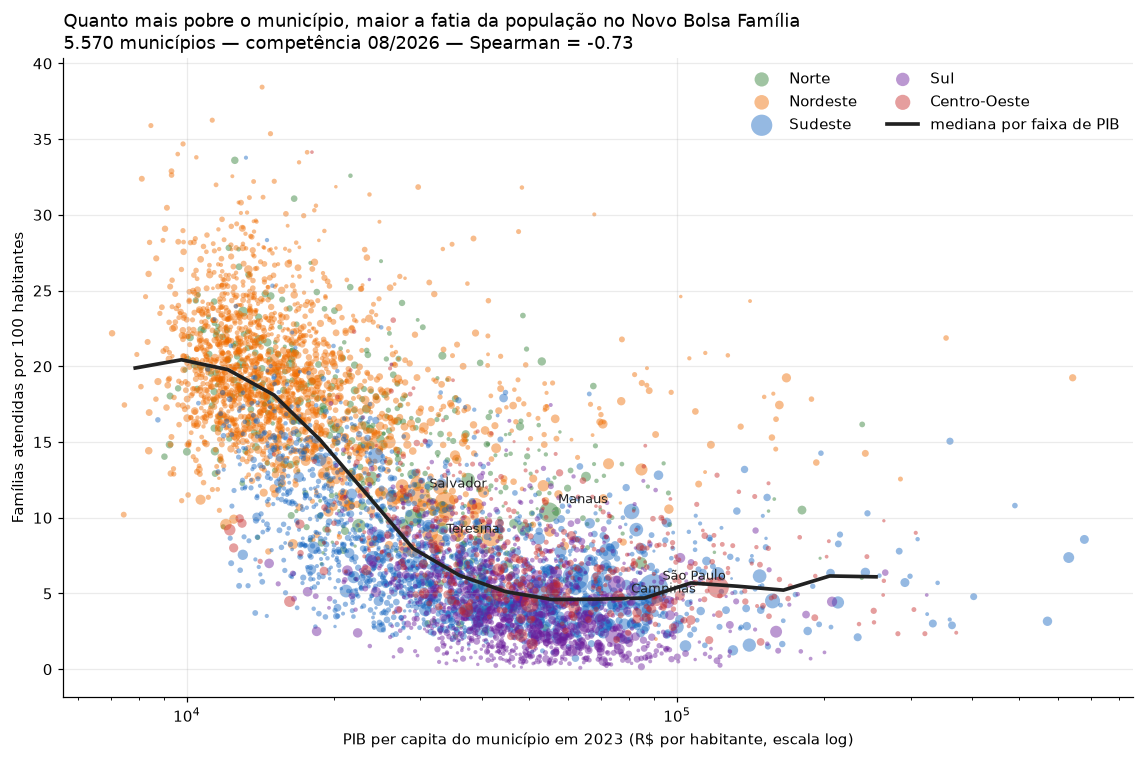

In [8]:
import numpy as np

fig, ax = plt.subplots(figsize=(10.5, 7))

for regiao, cor in CORES_REGIAO.items():
    parte = mun[mun["regiao"] == regiao]
    ax.scatter(parte["pib_per_capita"], parte["familias_por_100_hab"],
               s=np.sqrt(parte["populacao"]) / 9, alpha=0.45, color=cor,
               edgecolors="none", label=regiao)

# Tendência: mediana da dependência dentro de faixas de PIB per capita.
faixas = np.logspace(np.log10(mun["pib_per_capita"].min()),
                     np.log10(mun["pib_per_capita"].max()), 22)
centros, medianas = [], []
for inicio, fim in zip(faixas[:-1], faixas[1:]):
    dentro = mun[(mun["pib_per_capita"] >= inicio) & (mun["pib_per_capita"] < fim)]
    if len(dentro) >= 15:
        centros.append(np.sqrt(inicio * fim))
        medianas.append(dentro["familias_por_100_hab"].median())
ax.plot(centros, medianas, color="#212121", linewidth=2.4,
        label="mediana por faixa de PIB")

for nome in ["São Paulo", "Campinas", "Salvador", "Manaus", "Teresina"]:
    linha = mun[mun["municipio"] == nome]
    if not linha.empty:
        linha = linha.iloc[0]
        ax.annotate(nome, (linha["pib_per_capita"], linha["familias_por_100_hab"]),
                    textcoords="offset points", xytext=(6, 6), fontsize=8.5,
                    color="#212121",
                    arrowprops=dict(arrowstyle="-", color="#9E9E9E", lw=0.8))

ax.set_xscale("log")
ax.set_xlabel("PIB per capita do município em 2023 (R$ por habitante, escala log)")
ax.set_ylabel("Famílias atendidas por 100 habitantes")
ax.set_title("Quanto mais pobre o município, maior a fatia da população no "
             "Novo Bolsa Família\n"
             f"5.570 municípios — competência {str(COMPETENCIA)[4:]}/"
             f"{str(COMPETENCIA)[:4]} — Spearman = {correlacao:.2f}",
             fontsize=12, loc="left")
ax.legend(frameon=False, loc="upper right", ncols=2)
fig.tight_layout()
fig.savefig(PASTA / "viz2_pib_x_dependencia.png", bbox_inches="tight")
plt.show()

**O que se conclui.** A nuvem desce da esquerda para a direita e a linha preta
(mediana por faixa de PIB) cai de forma contínua: municípios com PIB per capita
abaixo de R$ 20 mil têm, com frequência, mais de 10 famílias atendidas para cada
100 habitantes, enquanto municípios acima de R$ 80 mil raramente passam de 4. A
correlação de Spearman negativa confirma o que o gráfico mostra. O programa está,
de fato, chegando onde a economia local é mais fraca — que é exatamente o
critério de focalização que se espera dele.

## 4. Visualização 3 — Mapa do país

**Objetivo.** Traduzir o resultado da Visualização 1 em geografia, para
enxergar de uma vez o recorte regional.

**Atributos envolvidos.** `valor_per_capita` por UF (Bases 1 e 2 combinadas) e a
malha territorial oficial do IBGE em GeoJSON, obtida pela API de malhas.

In [9]:
import requests

from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as PoligonoMPL

URL_MALHA = ("https://servicodados.ibge.gov.br/api/v3/malhas/paises/BR"
             "?formato=application/vnd.geo+json&qualidade=intermediaria"
             "&intrarregiao=UF")

# A API responde com Content-Encoding: gzip; o requests descompacta sozinho
# (com urllib seria preciso tratar o cabeçalho na mão).
malha = requests.get(URL_MALHA, timeout=180).json()

# A malha identifica cada UF pelo código numérico do IBGE; o resumo usa a sigla.
codigo_para_sigla = {
    str(d["uf_id"]): d["uf_sigla"]
    for d in db["municipios_ibge"].aggregate([
        {"$group": {"_id": "$uf_sigla", "uf_id": {"$first": "$uf_id"},
                    "uf_sigla": {"$first": "$uf_sigla"}}}])
}
valor = dict(zip(uf["uf"], uf["valor_per_capita"]))
print(f"{len(malha['features'])} polígonos de UF recebidos do IBGE")

27 polígonos de UF recebidos do IBGE


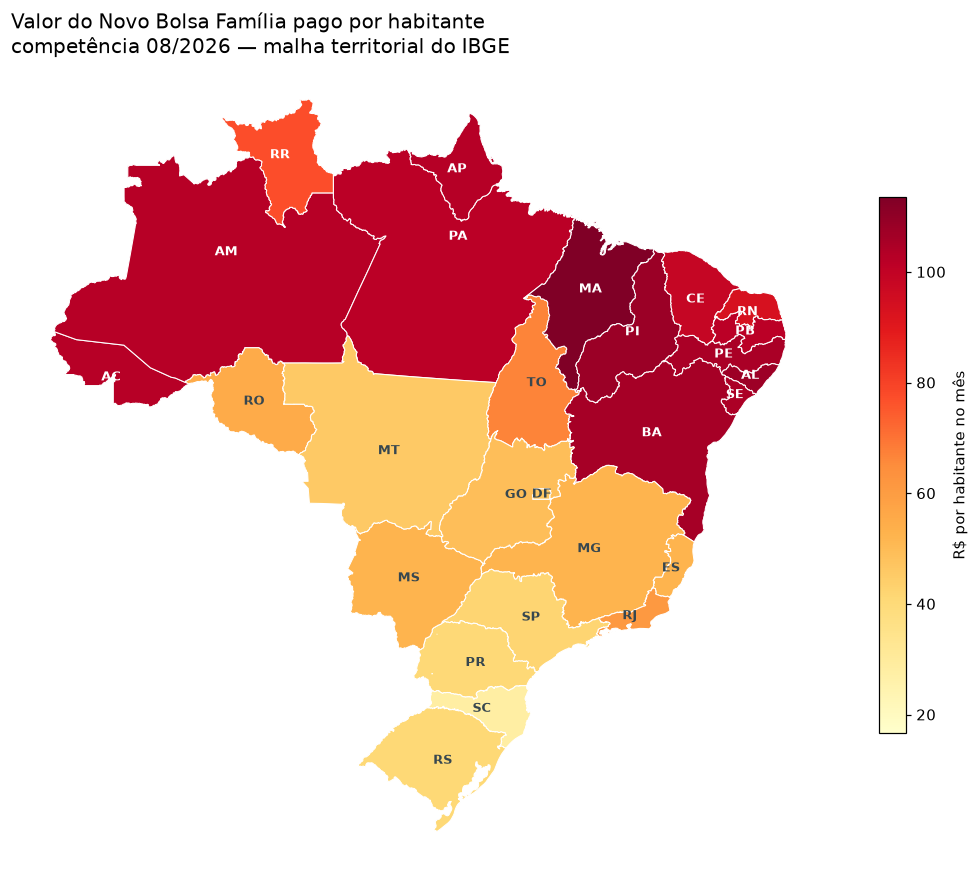

In [10]:
fig, ax = plt.subplots(figsize=(9, 9))

mapa_cores = plt.get_cmap("YlOrRd")
minimo, maximo = min(valor.values()), max(valor.values())
poligonos, cores, rotulos = [], [], []

for feicao in malha["features"]:
    sigla = codigo_para_sigla.get(str(feicao["properties"]["codarea"]))
    if sigla is None:
        continue
    intensidade = (valor[sigla] - minimo) / (maximo - minimo)
    geometria = feicao["geometry"]
    partes = ([geometria["coordinates"]] if geometria["type"] == "Polygon"
              else geometria["coordinates"])
    maior, area_maior = None, -1
    for parte in partes:
        anel = np.array(parte[0])
        poligonos.append(PoligonoMPL(anel, closed=True))
        cores.append(mapa_cores(0.12 + 0.88 * intensidade))
        area = (anel[:, 0].max() - anel[:, 0].min()) * (anel[:, 1].max() - anel[:, 1].min())
        if area > area_maior:
            area_maior, maior = area, anel
    rotulos.append((maior[:, 0].mean(), maior[:, 1].mean(), sigla, intensidade))

ax.add_collection(PatchCollection(poligonos, facecolors=cores,
                                  edgecolors="white", linewidths=0.7))
for x, y, sigla, intensidade in rotulos:
    ax.text(x, y, sigla, ha="center", va="center", fontsize=8.5, weight="bold",
            color="white" if intensidade > 0.55 else "#37474F")

ax.autoscale_view()
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Valor do Novo Bolsa Família pago por habitante\n"
             f"competência {str(COMPETENCIA)[4:]}/{str(COMPETENCIA)[:4]} — "
             "malha territorial do IBGE", fontsize=13, loc="left")

barra = fig.colorbar(plt.cm.ScalarMappable(
    norm=matplotlib.colors.Normalize(vmin=minimo, vmax=maximo), cmap=mapa_cores),
    ax=ax, fraction=0.03, pad=0.01)
barra.set_label("R$ por habitante no mês")
fig.tight_layout()
fig.savefig(PASTA / "viz3_mapa_valor_per_capita.png", bbox_inches="tight")
plt.show()

**O que se conclui.** O mapa mostra uma mancha contínua de tons escuros cobrindo
todo o Nordeste e avançando pelo Norte, e tons claros no Sul, no Sudeste e no
Centro-Oeste. Duas leituras práticas: para quem formula política pública, o mapa
indica onde uma eventual mudança de regra do programa teria maior impacto
econômico regional; para quem lê a notícia, ele mostra que discutir o Bolsa
Família é discutir, na prática, a renda do Norte e do Nordeste.

## 5. Visualização 4 — Como a dependência se distribui entre os municípios

**Objetivo.** Sair da média e olhar a distribuição completa: quantos municípios
estão em cada nível de dependência do programa, e quanto do dinheiro vai para
cada porte de cidade.

**Atributos envolvidos.** `familias_por_100_hab` e `total_pago` (Bases 1 e 2
combinadas), `populacao` (IBGE) para classificar o porte do município.

resumo_municipio_competencia: 7 documentos em 22 ms


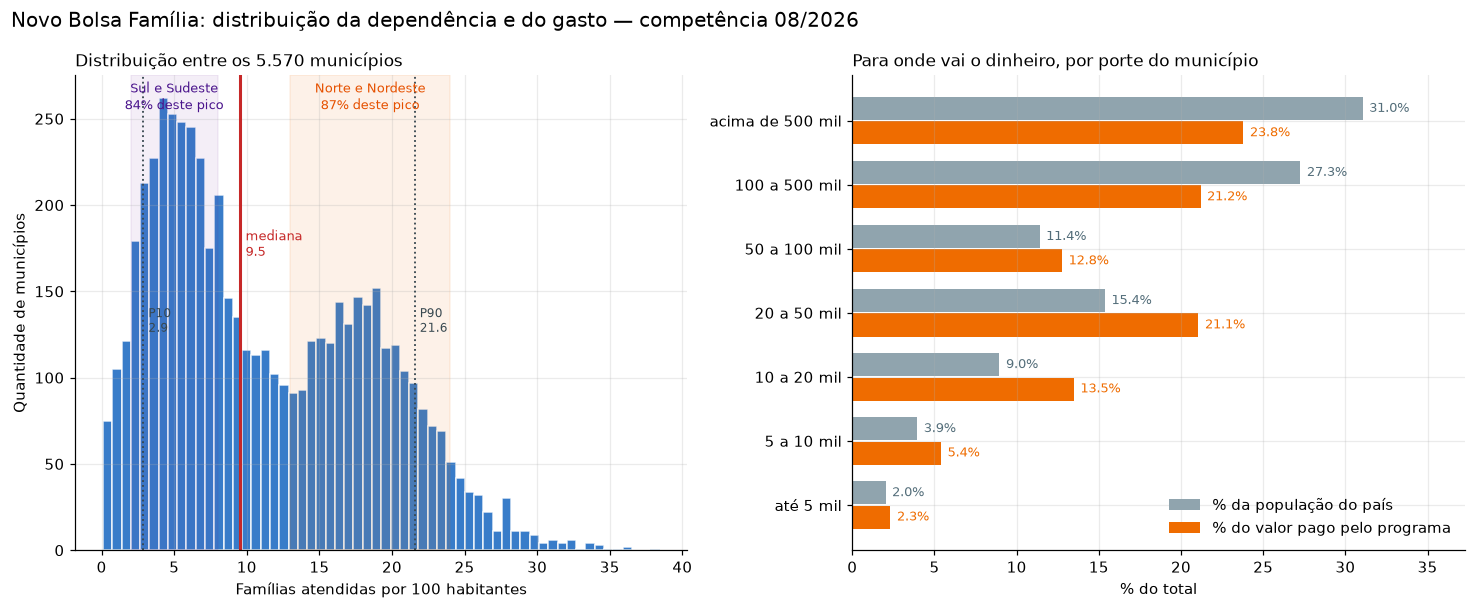

,faixa,municipios,populacao,familias,total_pago,pct_pop,pct_pago
0,até 5 mil,1286,4330543,438065,"295,976,242.00",2.02,2.32
1,5 a 10 mil,1181,8458546,1011070,"688,828,052.00",3.95,5.40
2,10 a 20 mil,1349,19179699,2516861,"1,720,363,053.00",8.95,13.48
3,20 a 50 mil,1068,32928308,3913893,"2,687,981,518.00",15.37,21.06
4,50 a 100 mil,349,24411699,2385213,"1,628,997,108.00",11.40,12.76
5,100 a 500 mil,289,58395565,3982023,"2,704,187,204.00",27.26,21.19
6,acima de 500 mil,49,66507591,4531501,"3,036,916,582.00",31.05,23.79


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6))

# --- painel esquerdo: distribuição entre os 5.570 municípios ---------------
dados = mun["familias_por_100_hab"]
ax1.hist(dados, bins=60, color="#1565C0", alpha=0.85, edgecolor="white")
topo = ax1.get_ylim()[1]

# A distribuição tem duas modas, e cada uma corresponde a um bloco de regiões.
ax1.axvspan(2, 8, color="#6A1B9A", alpha=0.07)
ax1.axvspan(13, 24, color="#EF6C00", alpha=0.09)
ax1.text(5, topo * 0.99, "Sul e Sudeste\n84% deste pico", ha="center", va="top",
         fontsize=8.5, color="#4A148C")
ax1.text(18.5, topo * 0.99, "Norte e Nordeste\n87% deste pico", ha="center",
         va="top", fontsize=8.5, color="#E65100")

mediana = dados.median()
ax1.axvline(mediana, color="#C62828", linewidth=2)
ax1.text(mediana + 0.4, topo * 0.62, f"mediana\n{mediana:.1f}", color="#C62828",
         fontsize=8.5)
for percentil, altura in ((10, 0.46), (90, 0.46)):
    x = np.percentile(dados, percentil)
    ax1.axvline(x, color="#37474F", linestyle=":", linewidth=1.2)
    ax1.text(x + 0.35, topo * altura, f"P{percentil}\n{x:.1f}", color="#37474F",
             fontsize=8)
ax1.set_ylim(0, topo)
ax1.set_xlabel("Famílias atendidas por 100 habitantes")
ax1.set_ylabel("Quantidade de municípios")
ax1.set_title("Distribuição entre os 5.570 municípios", fontsize=11, loc="left")

# --- painel direito: para onde vai o dinheiro, por porte de cidade ---------
pipeline_porte = [
    {"$match": {"competencia": COMPETENCIA, "populacao": {"$gt": 0}}},
    {"$bucket": {
        "groupBy": "$populacao",
        "boundaries": [0, 5000, 10000, 20000, 50000, 100000, 500000, 100000000],
        "output": {"municipios": {"$sum": 1},
                   "total_pago": {"$sum": "$total_pago"},
                   "familias": {"$sum": "$parcelas_regulares"},
                   "populacao": {"$sum": "$populacao"}}}},
]
porte = agregar(RESUMO, pipeline_porte)
nomes = ["até 5 mil", "5 a 10 mil", "10 a 20 mil", "20 a 50 mil",
         "50 a 100 mil", "100 a 500 mil", "acima de 500 mil"]
porte["faixa"] = nomes[:len(porte)]
porte["pct_pago"] = 100 * porte["total_pago"] / porte["total_pago"].sum()
porte["pct_pop"] = 100 * porte["populacao"] / porte["populacao"].sum()

y = np.arange(len(porte))
ax2.barh(y + 0.19, porte["pct_pop"], height=0.36, color="#90A4AE",
         label="% da população do país")
ax2.barh(y - 0.19, porte["pct_pago"], height=0.36, color="#EF6C00",
         label="% do valor pago pelo programa")
for i, (pago, pop) in enumerate(zip(porte["pct_pago"], porte["pct_pop"])):
    ax2.text(pago + 0.4, i - 0.19, f"{pago:.1f}%", va="center", fontsize=8.5,
             color="#EF6C00")
    ax2.text(pop + 0.4, i + 0.19, f"{pop:.1f}%", va="center", fontsize=8.5,
             color="#546E7A")
ax2.set_yticks(y, porte["faixa"])
ax2.set_xlabel("% do total")
ax2.set_title("Para onde vai o dinheiro, por porte do município",
              fontsize=11, loc="left")
ax2.legend(frameon=False, loc="lower right")
ax2.set_xlim(0, max(porte["pct_pago"].max(), porte["pct_pop"].max()) * 1.2)

fig.suptitle("Novo Bolsa Família: distribuição da dependência e do gasto — "
             f"competência {str(COMPETENCIA)[4:]}/{str(COMPETENCIA)[:4]}",
             fontsize=13, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(PASTA / "viz4_distribuicao_e_porte.png", bbox_inches="tight")
plt.show()

porte[["faixa", "municipios", "populacao", "familias", "total_pago",
       "pct_pop", "pct_pago"]]

**O que se conclui.** O resultado mais forte do trabalho está no painel da
esquerda: a distribuição é **bimodal**. Não existe um "município brasileiro
médio" no programa — existem dois grupos separados por um vale por volta de
10 famílias por 100 habitantes.

* **Primeira moda, em torno de 4 a 6 famílias por 100 habitantes:** 2.117
  municípios, dos quais **84% são do Sul e do Sudeste** e apenas 2 são do
  Nordeste.
* **Segunda moda, em torno de 17 a 19:** 1.927 municípios, dos quais **87% são
  do Norte e do Nordeste**.

As medianas regionais confirmam a leitura: Nordeste 18,9, Norte 14,5,
Centro-Oeste 7,2, Sudeste 6,8 e Sul 4,0 famílias por 100 habitantes. Em outras
palavras, a mediana nacional de 9,5 cai justamente no vale entre os dois grupos —
é uma média que não descreve quase nenhum município de verdade.

O painel da direita mostra o mesmo fenômeno pelo eixo do porte da cidade: nos
municípios de até 50 mil habitantes a barra laranja (fatia do dinheiro) supera a
cinza (fatia da população), e nas cidades acima de 500 mil ocorre o inverso —
31,0% da população recebendo 23,8% do valor.

## 6. Consulta direta na coleção de 57 milhões de parcelas

As visualizações acima usam a visão materializada (`$merge`), com cerca de 16,7
mil documentos. A célula abaixo mostra uma consulta indo direto na coleção
`pagamentos_bf` completa, usando o índice `{cod_ibge, competencia, valor}`
criado no item (g): mesmo com 57 milhões de documentos, a resposta sai em
milissegundos.

In [12]:
COD_IBGE = 3509502   # Campinas (SP)

inicio = time.perf_counter()
faixas = list(db["pagamentos_bf"].aggregate([
    {"$match": {"cod_ibge": COD_IBGE, "competencia": COMPETENCIA}},
    {"$bucket": {
        "groupBy": "$valor",
        "boundaries": [0, 200, 400, 600, 800, 1000, 1500, 100000],
        "default": "outros",
        "output": {"parcelas": {"$sum": 1}, "total": {"$sum": "$valor"}}}},
]))
print(f"tempo: {(time.perf_counter()-inicio)*1000:,.0f} ms")

rotulos = {0: "até R$ 200", 200: "R$ 200 a 400", 400: "R$ 400 a 600",
           600: "R$ 600 a 800", 800: "R$ 800 a 1.000",
           1000: "R$ 1.000 a 1.500", 1500: "acima de R$ 1.500"}
pd.DataFrame([{"faixa": rotulos.get(f["_id"], f["_id"]),
               "parcelas": f["parcelas"], "total": f["total"]} for f in faixas])

tempo: 63 ms


,faixa,parcelas,total
0,até R$ 200,3,100.00
1,R$ 200 a 400,5642,"1,893,730.00"
2,R$ 400 a 600,2417,"1,052,444.00"
3,R$ 600 a 800,32164,"21,224,618.00"
4,R$ 800 a 1.000,10607,"8,992,825.00"
5,R$ 1.000 a 1.500,2223,"2,508,372.00"
6,acima de R$ 1.500,110,"187,452.00"


In [13]:
# O plano de execução comprova que o índice está sendo usado.
# Cursor.explain() do PyMongo 4 não aceita nível de detalhe, então pedimos o
# executionStats pelo comando explain do próprio servidor.
plano = db.command({
    "explain": {"find": "pagamentos_bf",
                "filter": {"cod_ibge": COD_IBGE, "competencia": COMPETENCIA},
                "sort": {"valor": -1}},
    "verbosity": "executionStats",
})

stats = plano["executionStats"]
estagio = plano["queryPlanner"]["winningPlan"]
nome_indice = repr(estagio).split("'indexName': '")[1].split("'")[0] \
    if "indexName" in repr(estagio) else "(nenhum)"

pd.DataFrame([
    ("documentos na coleção", f"{db['pagamentos_bf'].estimated_document_count():,}"),
    ("índice utilizado", nome_indice),
    ("documentos examinados", f"{stats['totalDocsExamined']:,}"),
    ("chaves de índice lidas", f"{stats['totalKeysExamined']:,}"),
    ("documentos retornados", f"{stats['nReturned']:,}"),
    ("tempo (ms)", f"{stats['executionTimeMillis']:,}"),
], columns=["métrica", "valor"])

,métrica,valor
0,documentos na coleção,"57,174,504"
1,índice utilizado,idx_municipio_competencia_valor
2,documentos examinados,"53,166"
3,chaves de índice lidas,"53,166"
4,documentos retornados,"53,166"
5,tempo (ms),107


## 7. Em uma frase

Os dois conjuntos de dados, cruzados, mostram que o Novo Bolsa Família é um
programa territorialmente concentrado: ele transfere mais por habitante
exatamente nos estados e nos municípios de menor PIB per capita e de menor porte
populacional. Para quem mora no país, isso significa que a discussão sobre o
programa é, em boa medida, uma discussão sobre a renda do Norte e do Nordeste e
sobre a economia das cidades pequenas.